# EDA Brazilian e-commerce

In [ ]:
# Importar librerías que vamos a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

# Carga y exploración del dataset

In [ ]:
# Descargar dataset completo
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Ruta del dataset:", path)

# Archivos CSV de Olist
files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv"
}

# Cargar todos los CSV
dfs = {}

for name, filename in files.items():
  file_path = os.path.join(path, filename)
  dfs[name] = pd.read_csv(file_path)

tablas_con_duplicados = []

for name, df in dfs.items():
  print("=" * 60)
  print(f"DATASET: {name}")

  print(f"Forma: {df.shape}")
  print(f"Columnas: {list(df.columns)}")

  # 2. Explorar los datos básicamente
  print("\nPrimeras 5 filas:")
  print(df.head())  # método para mostrar las primeras filas del DataFrame

  # 3. Información sobre tipos de datos y memoria
  print("\nINFORMACIÓN GENERAL:")
  df.info()  # método que muestra tipos de datos, memoria y valores no nulos

  print("\nDUPLICADOS:")
  duplicados = df.duplicated().sum()
  if duplicados > 0:
    tablas_con_duplicados.append(name)
  print(duplicados)

  print("\nVALORES ÚNICOS POR COLUMNA:")
  print(df.nunique())

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Ruta del dataset: /kaggle/input/brazilian-ecommerce
DATASET: customers
Forma: (99441, 5)
Columnas: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Primeras 5 filas:
                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             S

## Valores Faltantes

In [ ]:
# ============================================================
# RESUMEN DE VALORES FALTANTES
# ============================================================

missing_summary = []

for name, df in dfs.items():
    for col in df.columns:
        missing = df[col].isna().sum()
        percentage = missing / len(df) * 100

        if missing > 0:
            missing_summary.append({
                "tabla": name,
                "columna": col,
                "faltantes": missing,
                "porcentaje": percentage
            })

missing_df = pd.DataFrame(missing_summary)

missing_df = missing_df.sort_values(
    ["tabla", "porcentaje"],
    ascending=[True, False]
)

missing_df

,tabla,columna,faltantes,porcentaje
0,order_reviews,review_comment_title,87656,88.341530
1,order_reviews,review_comment_message,58247,58.702532
4,orders,order_delivered_customer_date,2965,2.981668
3,orders,order_delivered_carrier_date,1783,1.793023
2,orders,order_approved_at,160,0.160899
5,products,product_category_name,610,1.851234
6,products,product_name_lenght,610,1.851234
7,products,product_description_lenght,610,1.851234
8,products,product_photos_qty,610,1.851234
9,products,product_weight_g,2,0.006070


### Análisis de valores faltantes en tabla orders

In [ ]:
orders = dfs["orders"]

date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

for col in date_columns:
    print("=" * 50)
    print(col)

    print(
        orders.loc[orders[col].isna(), "order_status"]
        .value_counts()
    )

order_approved_at
order_status
canceled     141
delivered     14
created        5
Name: count, dtype: int64
order_delivered_carrier_date
order_status
unavailable    609
canceled       550
invoiced       314
processing     301
created          5
approved         2
delivered        2
Name: count, dtype: int64
order_delivered_customer_date
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


### Hallazgo sobre valores faltantes en fechas

Los valores faltantes en las fechas del ciclo del pedido no se consideran automáticamente errores. En muchos casos están asociados a estados como `canceled`, `processing`, `shipped` o `unavailable`, por lo que la ausencia de una fecha de entrega puede ser coherente con el estado del pedido.

## Validación de claves y granularidad

Además de buscar filas completamente duplicadas, se analiza si las claves esperadas son únicas y cuál es la unidad de observación de cada tabla.

In [ ]:
key_checks = {
    "customers.customer_id":
        dfs["customers"]["customer_id"].duplicated().sum(),

    "orders.order_id":
        dfs["orders"]["order_id"].duplicated().sum(),

    "products.product_id":
        dfs["products"]["product_id"].duplicated().sum(),

    "sellers.seller_id":
        dfs["sellers"]["seller_id"].duplicated().sum(),

    "order_items (order_id + order_item_id)":
        dfs["order_items"].duplicated(
            subset=["order_id", "order_item_id"]
        ).sum(),

    "order_payments (order_id + payment_sequential)":
        dfs["order_payments"].duplicated(
            subset=["order_id", "payment_sequential"]
        ).sum()
}

pd.Series(key_checks, name="duplicados")

,duplicados
customers.customer_id,0
orders.order_id,0
products.product_id,0
sellers.seller_id,0
order_items (order_id + order_item_id),0
order_payments (order_id + payment_sequential),0


## Integridad referencial

In [ ]:
checks_fk = {
    "orders -> customers":
        (~dfs["orders"]["customer_id"]
         .isin(dfs["customers"]["customer_id"])).sum(),

    "order_items -> orders":
        (~dfs["order_items"]["order_id"]
         .isin(dfs["orders"]["order_id"])).sum(),

    "order_items -> products":
        (~dfs["order_items"]["product_id"]
         .isin(dfs["products"]["product_id"])).sum(),

    "order_items -> sellers":
        (~dfs["order_items"]["seller_id"]
         .isin(dfs["sellers"]["seller_id"])).sum(),

    "payments -> orders":
        (~dfs["order_payments"]["order_id"]
         .isin(dfs["orders"]["order_id"])).sum(),

    "reviews -> orders":
        (~dfs["order_reviews"]["order_id"]
         .isin(dfs["orders"]["order_id"])).sum()
}

pd.Series(checks_fk, name="registros_sin_correspondencia")

,registros_sin_correspondencia
orders -> customers,0
order_items -> orders,0
order_items -> products,0
order_items -> sellers,0
payments -> orders,0
reviews -> orders,0


## Limpieza de Duplicados

In [ ]:
for tabla in tablas_con_duplicados:
  df = dfs[tabla]
  df.drop_duplicates(inplace=True)
  print(f'>>> {tabla} tiene ' + str(df.duplicated().sum()) + ' duplicados.')

>>> geolocation tiene 0 duplicados.


## Conversión de Fecha

In [ ]:
orders_clean = dfs["orders"].copy()

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

## Conversión de abreviatura de estados a nombre completo


In [ ]:
states = pd.DataFrame({
    "state_code": [
        "SP", "RJ", "MG", "RS", "PR", "SC", "BA", "DF", "GO",
        "ES", "PE", "CE", "PA", "MT", "MA", "MS", "PB", "PI",
        "RN", "AL", "SE", "TO", "RO", "AM", "AC", "AP", "RR"
    ],
    "state_name": [
        "São Paulo", "Rio de Janeiro", "Minas Gerais", "Rio Grande do Sul",
        "Paraná", "Santa Catarina", "Bahia", "Distrito Federal", "Goiás",
        "Espírito Santo", "Pernambuco", "Ceará", "Pará", "Mato Grosso",
        "Maranhão", "Mato Grosso do Sul", "Paraíba", "Piauí",
        "Rio Grande do Norte", "Alagoas", "Sergipe", "Tocantins",
        "Rondônia", "Amazonas", "Acre", "Amapá", "Roraima"
    ]
})

## Exploración orientada a las preguntas de dominio

La exploración se centra en identificar patrones geográficos, comerciales y logísticos que permitan responder las preguntas planteadas para el análisis.

En particular, se analizará la distribución de las ventas por ubicación, la facturación promedio por pedido, los costos de envío, los tiempos de entrega y la satisfacción de los clientes. Para ello será necesario integrar información proveniente de las tablas de pedidos, clientes, vendedores, productos, ítems de pedidos y reseñas.

#### Construcción de una tabla analítica de pedidos

Para facilitar el análisis se integran las principales fuentes relacionadas con los pedidos. La tabla resultante permitirá asociar cada pedido con su ubicación, importe, costo de envío, información temporal y satisfacción del cliente.

Se utilizará el pedido como unidad principal de análisis, evitando contar varias veces un mismo pedido cuando contiene múltiples productos.

In [ ]:
# ============================================================
# CONSTRUCCIÓN DE TABLA ANALÍTICA
# ============================================================

orders = orders_clean.copy()
customers = dfs["customers"].copy()
order_items = dfs["order_items"].copy()
reviews = dfs["order_reviews"].copy()

# ------------------------------------------------------------
# 1. Valor total y costo total de envío por pedido
# ------------------------------------------------------------

order_values = (
    order_items
    .groupby("order_id")
    .agg(
        facturacion=("price", "sum"),
        costo_envio=("freight_value", "sum"),
        cantidad_items=("order_item_id", "count")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Información del cliente
# ------------------------------------------------------------

customer_info = customers[
    [
        "customer_id",
        "customer_unique_id",
        "customer_city",
        "customer_state"
    ]
]

# ------------------------------------------------------------
# 3. Unir pedidos + clientes
# ------------------------------------------------------------

orders_analysis = orders.merge(
    customer_info,
    on="customer_id",
    how="left"
)

# ------------------------------------------------------------
# 4. Agregar información económica
# ------------------------------------------------------------

orders_analysis = orders_analysis.merge(
    order_values,
    on="order_id",
    how="left"
)

# ------------------------------------------------------------
# 5. Agregar satisfacción
# ------------------------------------------------------------

review_info = (
    reviews
    .groupby("order_id")
    .agg(
        review_score=("review_score", "mean")
    )
    .reset_index()
)

orders_analysis = orders_analysis.merge(
    review_info,
    on="order_id",
    how="left"
)

print("Forma de la tabla analítica:", orders_analysis.shape)

orders_analysis.head()

Forma de la tabla analítica: (99441, 15)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,facturacion,costo_envio,cantidad_items,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,29.99,8.72,1.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,barreiras,BA,118.70,22.76,1.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO,159.90,19.22,1.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN,45.00,27.20,1.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP,19.90,8.72,1.0,5.0


#### Concentración geográfica de las ventas

Se analiza la distribución de los pedidos según el estado del cliente. Esta primera aproximación permite identificar las regiones donde se concentra la actividad comercial.

La cantidad de pedidos se utiliza como indicador de volumen de ventas, evitando que un mismo pedido sea contabilizado varias veces por contener múltiples productos.

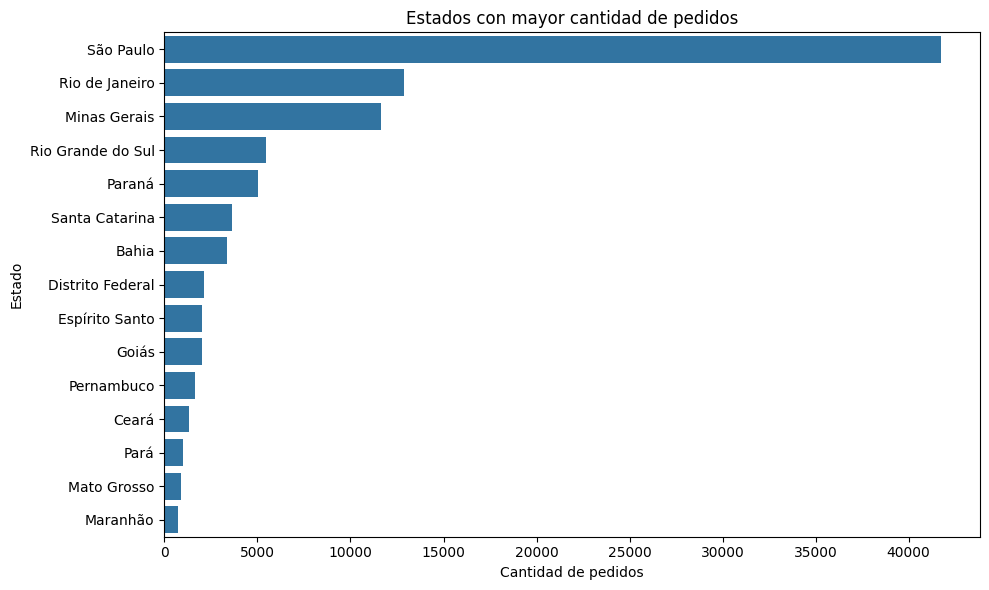

In [ ]:
# ============================================================
# PEDIDOS POR ESTADO
# ============================================================

orders_analysis_states = orders_analysis.merge(
    states,
    left_on="customer_state",
    right_on="state_code",
    how="left"
)

sales_by_state = (
    orders_analysis_states
    .groupby("state_name")
    .agg(
        pedidos=("order_id", "nunique"),
        facturacion=("facturacion", "sum")
    )
    .sort_values("pedidos", ascending=False)
)

sales_by_state.head(15)

# ============================================================
# GRÁFICO: PEDIDOS POR ESTADO
# ============================================================

top_states = sales_by_state.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_states.reset_index(),
    x="pedidos",
    y="state_name"
)

plt.title("Estados con mayor cantidad de pedidos")
plt.xlabel("Cantidad de pedidos")
plt.ylabel("Estado")

plt.tight_layout()
plt.show()

#### Concentración de ventas por ciudad

A nivel urbano, se identifican las ciudades con mayor cantidad de pedidos. Se muestran únicamente las principales ciudades para facilitar la comparación y evitar que las numerosas localidades de baja frecuencia oculten los patrones relevantes.

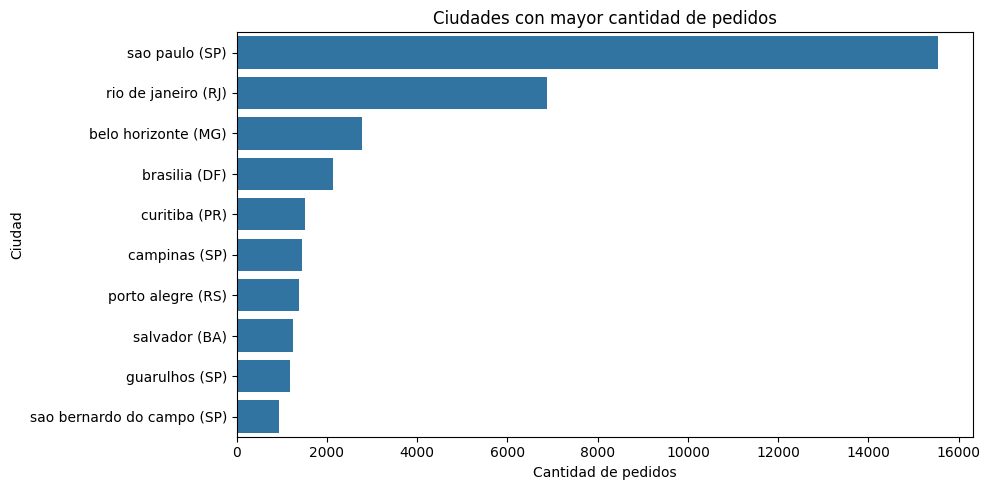

In [ ]:
# ============================================================
# PEDIDOS POR CIUDAD
# ============================================================

sales_by_city = (
    orders_analysis
    .groupby(["customer_state", "customer_city"])
    .agg(
        pedidos=("order_id", "nunique"),
        facturacion=("facturacion", "sum")
    )
    .reset_index()
    .sort_values("pedidos", ascending=False)
)

sales_by_city.head(10)
# ============================================================
# GRÁFICO: PRINCIPALES CIUDADES
# ============================================================

top_cities = sales_by_city.head(10).copy()

top_cities["ciudad_estado"] = (
    top_cities["customer_city"]
    + " ("
    + top_cities["customer_state"]
    + ")"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_cities,
    x="pedidos",
    y="ciudad_estado"
)

plt.title("Ciudades con mayor cantidad de pedidos")
plt.xlabel("Cantidad de pedidos")
plt.ylabel("Ciudad")

plt.tight_layout()
plt.show()

#### Facturación promedio por pedido

La cantidad de pedidos permite medir el volumen de ventas, pero no necesariamente el valor económico de cada operación. Por ello, se calcula la facturación promedio por pedido para comparar el valor medio de las transacciones entre regiones.

Se prioriza el análisis por estado para obtener resultados más robustos, ya que algunas ciudades presentan un número reducido de pedidos.

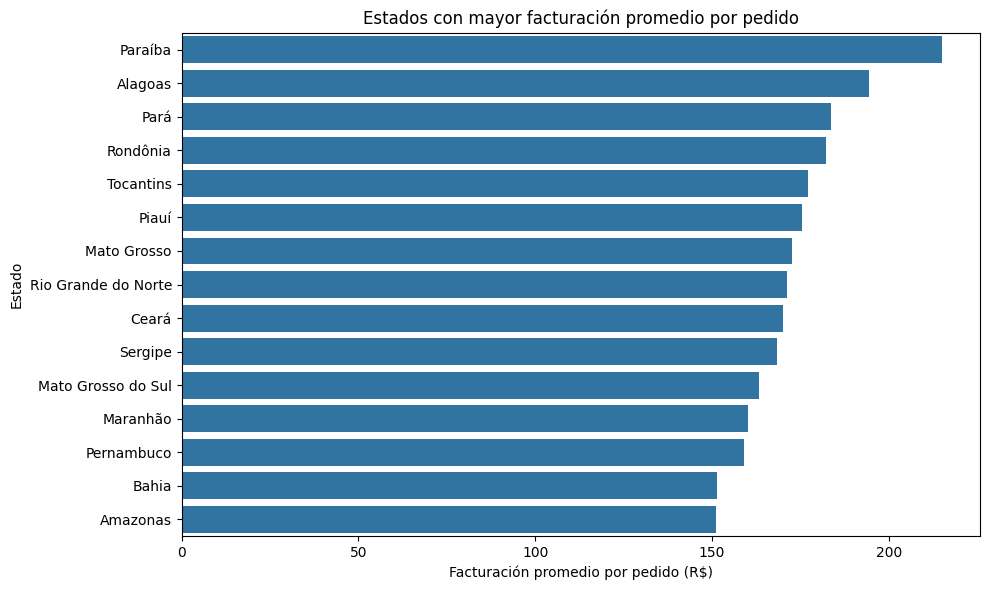

In [ ]:
# ============================================================
# FACTURACIÓN PROMEDIO POR PEDIDO
# ============================================================

orders_analysis_states = orders_analysis.merge(
    states,
    left_on="customer_state",
    right_on="state_code",
    how="left"
)

avg_revenue_state = (
    orders_analysis_states
    .groupby("state_name")
    .agg(
        pedidos=("order_id", "nunique"),
        facturacion_total=("facturacion", "sum")
    )
)

avg_revenue_state["facturacion_promedio"] = (
    avg_revenue_state["facturacion_total"]
    / avg_revenue_state["pedidos"]
)

# Para evitar conclusiones sobre regiones con muy pocos pedidos
avg_revenue_state = (
    avg_revenue_state[
        avg_revenue_state["pedidos"] >= 100
    ]
    .sort_values(
        "facturacion_promedio",
        ascending=False
    )
)

avg_revenue_state.head(15)

# ============================================================
# GRÁFICO: FACTURACIÓN PROMEDIO
# ============================================================

top_avg_revenue = avg_revenue_state.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_avg_revenue.reset_index(),
    x="facturacion_promedio",
    y="state_name"
)

plt.title("Estados con mayor facturación promedio por pedido")
plt.xlabel("Facturación promedio por pedido (R$)")
plt.ylabel("Estado")

plt.tight_layout()
plt.show()

#### Costos de envío por región

Se compara el costo promedio de envío entre estados para identificar diferencias geográficas en los costos logísticos.

Además del valor absoluto del envío, se analizará posteriormente su relación con la facturación del pedido, ya que un mismo costo puede tener distinta relevancia dependiendo del valor de la compra.

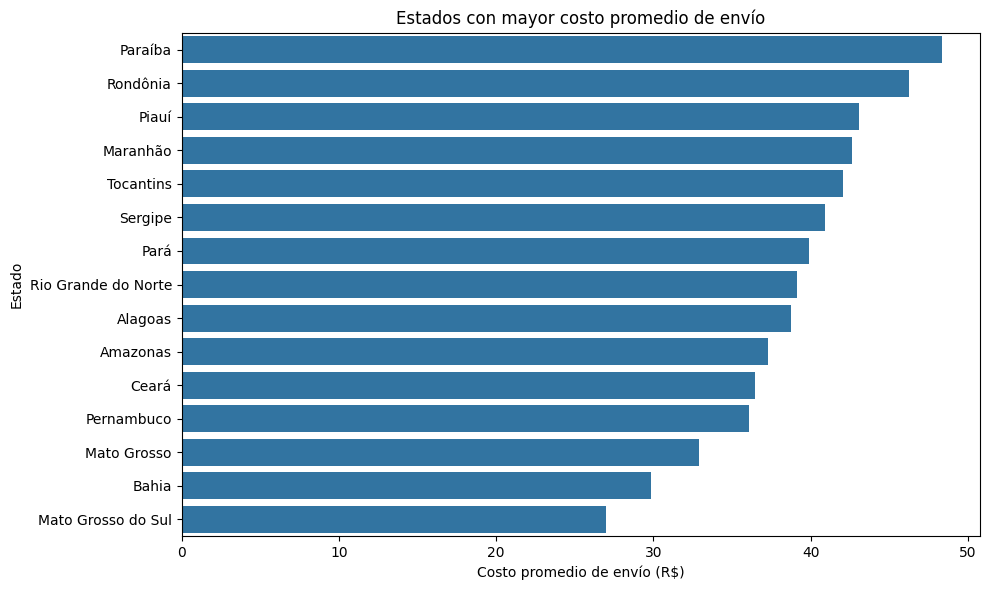

In [ ]:
# ============================================================
# COSTO DE ENVÍO PROMEDIO POR ESTADO
# ============================================================

orders_analysis_states = orders_analysis.merge(
    states,
    left_on="customer_state",
    right_on="state_code",
    how="left"
)

shipping_by_state = (
    orders_analysis_states
    .groupby("state_name")
    .agg(
        pedidos=("order_id", "nunique"),
        costo_envio_promedio=("costo_envio", "mean")
    )
)

shipping_by_state = (
    shipping_by_state[
        shipping_by_state["pedidos"] >= 100
    ]
    .sort_values(
        "costo_envio_promedio",
        ascending=False
    )
)

shipping_by_state.head(15)

# ============================================================
# GRÁFICO: COSTO DE ENVÍO PROMEDIO
# ============================================================

top_shipping = shipping_by_state.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_shipping.reset_index(),
    x="costo_envio_promedio",
    y="state_name"
)

plt.title("Estados con mayor costo promedio de envío")
plt.xlabel("Costo promedio de envío (R$)")
plt.ylabel("Estado")

plt.tight_layout()
plt.show()